# Ridge Regression with a Degree-14 Polynomial

This notebook reproduces the idea in the lecture slide:

$$
\hat y(x_i)
=
\theta_0+\theta_1x_i+\theta_2x_i^2+\cdots+\theta_{14}x_i^{14}.
$$

Define the polynomial feature map

$$
\phi(x_i)
=
\begin{bmatrix}
1 & x_i & x_i^2 & \cdots & x_i^{14}
\end{bmatrix}.
$$

Then the model is

$$
\boxed{
\hat y=\Phi\theta
}
$$

and ridge regression minimizes

$$
\boxed{
J(\theta)
=
(y-\Phi\theta)^\top(y-\Phi\theta)
+
\lambda\,\theta^\top\theta.
}
$$

Equivalently,

$$
\boxed{
\hat\theta_\lambda
=
(\Phi^\top\Phi+\lambda I)^{-1}\Phi^\top y.
}
$$

The purpose of regularization is to reduce the extreme oscillations that a high-degree polynomial can produce when fit to a small noisy dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

rng = np.random.default_rng(4)

## 1. Generate a small noisy dataset

We deliberately use relatively few observations so that a degree-14 polynomial has enough flexibility to overfit.

The underlying trend is smooth, but the observations contain noise.

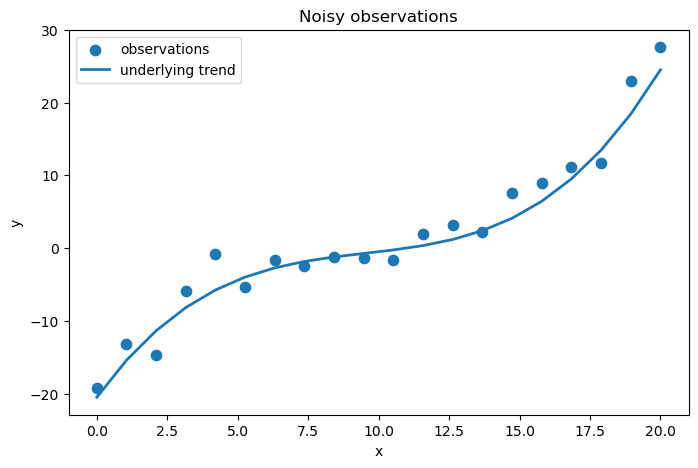

In [66]:
n = 20
x = np.linspace(0, 20, n)

# Smooth underlying signal
def f_true(x):
    return (
        -5
        + 0.45*x
        + 0.025*(x-10)**2
        + 0.018*(x-10)**3
    )

y_true = f_true(x)
y = y_true + rng.normal(0, 2.4, n)

plt.figure(figsize=(8,5))
plt.scatter(x, y, s=55, label="observations")
plt.plot(x, y_true, linewidth=2, label="underlying trend")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Noisy observations")
plt.legend()
plt.show()

## 2. Polynomial basis of degree 14

Directly using powers of \(x\) between 0 and 20 creates severe numerical scaling problems, because

$$
20^{14}
$$

is enormous.

So we first rescale \(x\) to approximately \([-1,1]\):

$$
\tilde x
=
\frac{x-\bar x}{\text{half-range}}.
$$

Then construct

$$
\Phi
=
\begin{bmatrix}
1 & \tilde x_1 & \tilde x_1^2 & \cdots & \tilde x_1^{14}\\
\vdots & \vdots & \vdots & & \vdots\\
1 & \tilde x_n & \tilde x_n^2 & \cdots & \tilde x_n^{14}
\end{bmatrix}.
$$

In [67]:
degree = 14

x_center = x.mean()
x_scale = (x.max() - x.min())/2
xs = (x - x_center)/x_scale

def poly_design(x_scaled, degree):
    return np.column_stack([x_scaled**k for k in range(degree+1)])

Phi = poly_design(xs, degree)

print("Design matrix shape:", Phi.shape)
print("Condition number of Phi^T Phi:", np.linalg.cond(Phi.T @ Phi))

Design matrix shape: (20, 15)
Condition number of Phi^T Phi: 44019299831.07407


## 3. Ridge objective

We use

$$
J_\lambda(\theta)
=
\|y-\Phi\theta\|_2^2
+
\lambda\|\theta\|_2^2.
$$

To avoid shrinking the intercept, we use the penalty matrix

$$
P=
\operatorname{diag}(0,1,1,\ldots,1).
$$

Then

$$
\boxed{
\hat\theta_\lambda
=
(\Phi^\top\Phi+\lambda P)^{-1}\Phi^\top y.
}
$$

In [68]:
P = np.eye(degree+1)
P[0,0] = 0.0

def ridge_fit(Phi, y, lam):
    A = Phi.T @ Phi + lam*P
    return np.linalg.solve(A, Phi.T @ y)

## 4. Compare small, medium, and large regularization

We now fit the same degree-14 polynomial with three different values of \(\lambda\).

- small \(\lambda\): weak regularization, highly flexible fit;
- medium \(\lambda\): smoother fit;
- large \(\lambda\): strong coefficient shrinkage and underfitting.

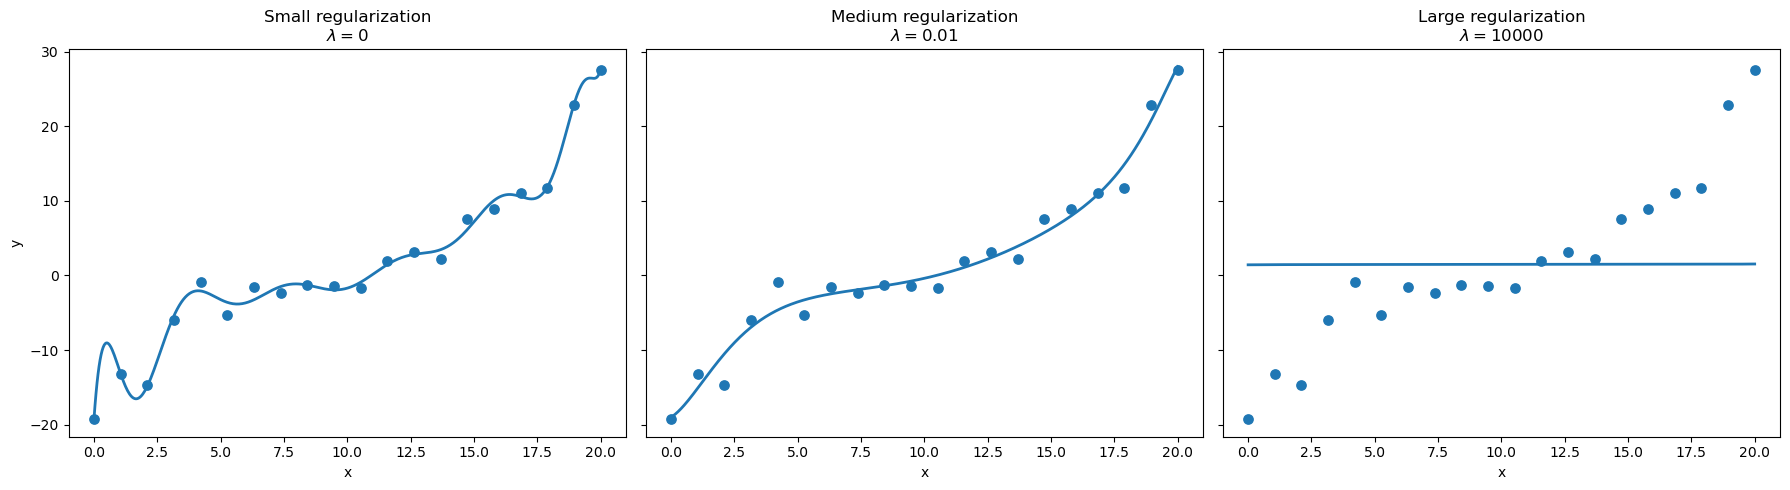

In [69]:
lambdas = [0, 1e-2, 10000]

xg = np.linspace(0,20,500)
xgs = (xg - x_center)/x_scale
Phi_g = poly_design(xgs, degree)

fits = {}

for lam in lambdas:
    theta = ridge_fit(Phi, y, lam)
    yg = Phi_g @ theta
    fits[lam] = (theta, yg)

fig, axes = plt.subplots(1,3,figsize=(18,5),sharey=True)

titles = ["Small regularization", "Medium regularization", "Large regularization"]

for ax, lam, title in zip(axes, lambdas, titles):
    theta, yg = fits[lam]
    ax.scatter(x,y,s=45)
    ax.plot(xg,yg,linewidth=2)
    ax.set_title(f"{title}\n$\\lambda={lam:g}$")
    ax.set_xlabel("x")

axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

The degree of the polynomial is unchanged:

$$
\boxed{\text{degree}=14}
$$

in every panel.

What changes is how strongly the coefficients are penalized.

## 5. What happens to the coefficients?

Ridge penalizes

$$
\theta_1^2+\cdots+\theta_{14}^2.
$$

As \(\lambda\) grows, the fitted coefficients are pushed toward zero.

In [70]:
rows = []

for lam in [0, 1e-8, 1e-4, 1e-2, 1e-1, 1, 10, 100]:
    if lam == 0:
        theta = np.linalg.lstsq(Phi,y,rcond=None)[0]
    else:
        theta = ridge_fit(Phi,y,lam)

    rows.append({
        "lambda":lam,
        "||theta_nonintercept||":np.linalg.norm(theta[1:]),
        "RSS":np.sum((y-Phi@theta)**2)
    })

summary = pd.DataFrame(rows)
summary

,lambda,||theta_nonintercept||,RSS
0,0.000000e+00,60710.174528,14.783563
1,1.000000e-08,8932.667570,17.234309
2,1.000000e-04,221.634498,44.294068
3,1.000000e-02,22.705164,68.750426
4,1.000000e-01,13.588216,76.999294
5,1.000000e+00,11.095449,98.508300
6,1.000000e+01,7.260021,397.304981
7,1.000000e+02,1.811940,1775.503051


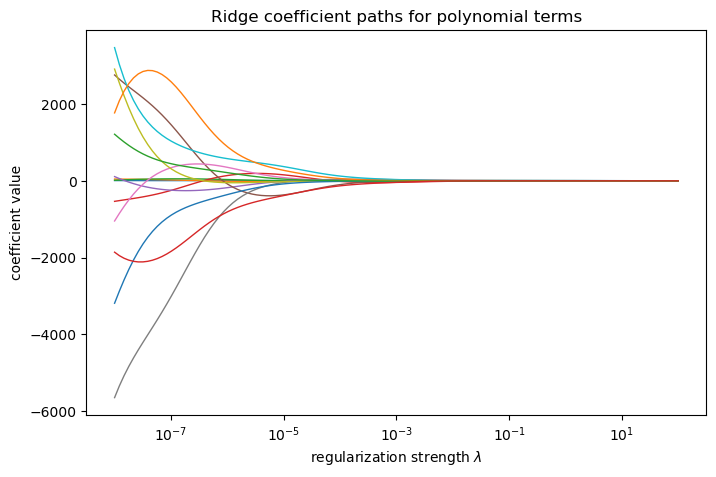

In [71]:
plt.figure(figsize=(8,5))

for k in range(1, degree+1):
    values = []
    lam_plot = np.logspace(-8,2,120)

    for lam in lam_plot:
        theta = ridge_fit(Phi,y,lam)
        values.append(theta[k])

    plt.semilogx(lam_plot, values, linewidth=1)

plt.xlabel(r"regularization strength $\lambda$")
plt.ylabel("coefficient value")
plt.title("Ridge coefficient paths for polynomial terms")
plt.show()

The higher-order terms are often the coefficients responsible for rapid oscillations.

Shrinking them makes the fitted curve smoother.

## 6. Training error versus regularization

As $\lambda$ increases, the model is no longer trying to minimize training RSS alone.

It minimizes

$$
RSS+\lambda\|\theta\|^2.
$$

Therefore training RSS typically increases with stronger regularization.

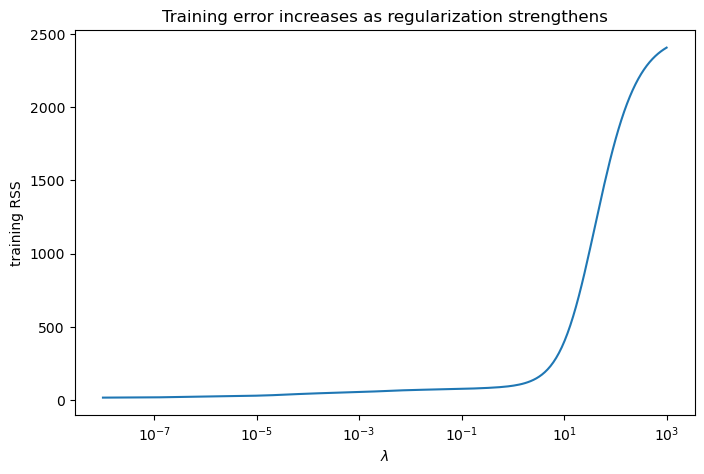

In [72]:
lam_grid = np.logspace(-8,3,200)

rss = []
penalty = []
objective = []

for lam in lam_grid:
    theta = ridge_fit(Phi,y,lam)
    r = y-Phi@theta

    rss.append(r@r)
    penalty.append(theta[1:]@theta[1:])
    objective.append(r@r + lam*(theta[1:]@theta[1:]))

plt.figure(figsize=(8,5))
plt.semilogx(lam_grid,rss,label="RSS")
plt.xlabel(r"$\lambda$")
plt.ylabel("training RSS")
plt.title("Training error increases as regularization strengthens")
plt.show()

## 7. Conditioning also improves

Ridge replaces

$$
\Phi^\top\Phi
$$

with

$$
\Phi^\top\Phi+\lambda P.
$$

Adding a positive diagonal term prevents small eigenvalues from getting too close to zero, thereby improving numerical conditioning.

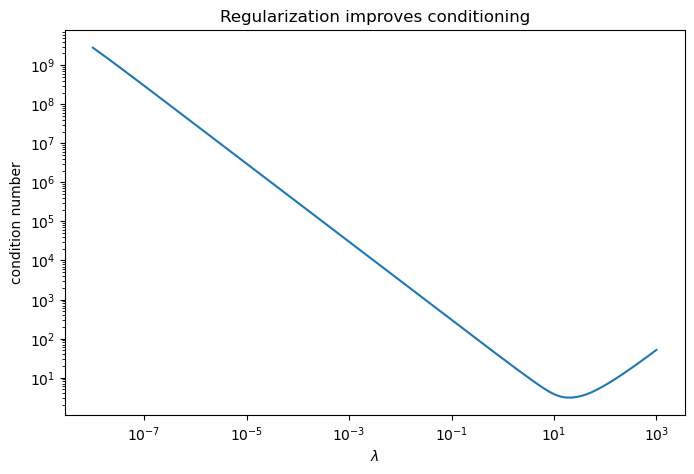

In [73]:
cond = []

for lam in lam_grid:
    A = Phi.T @ Phi + lam*P
    cond.append(np.linalg.cond(A))

plt.figure(figsize=(8,5))
plt.loglog(lam_grid,cond)
plt.xlabel(r"$\lambda$")
plt.ylabel("condition number")
plt.title("Regularization improves conditioning")
plt.show()

## 8. A more complete bias-variance picture

To see why ridge can improve generalization, split the dataset into training and validation points.

A very small \(\lambda\) may overfit the noisy training points.

A very large \(\lambda\) may oversmooth the curve.

An intermediate value often gives the best prediction error.

In [74]:
train_idx = np.arange(n) % 2 == 0
val_idx = ~train_idx

Phi_train = Phi[train_idx]
Phi_val = Phi[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

train_err = []
val_err = []

for lam in lam_grid:
    A = Phi_train.T @ Phi_train + lam*P
    theta = np.linalg.solve(A, Phi_train.T @ y_train)

    train_err.append(np.mean((y_train-Phi_train@theta)**2))
    val_err.append(np.mean((y_val-Phi_val@theta)**2))

best_idx = np.argmin(val_err)
best_lambda = lam_grid[best_idx]

print("Best validation lambda:", best_lambda)

Best validation lambda: 1.3354515629299029


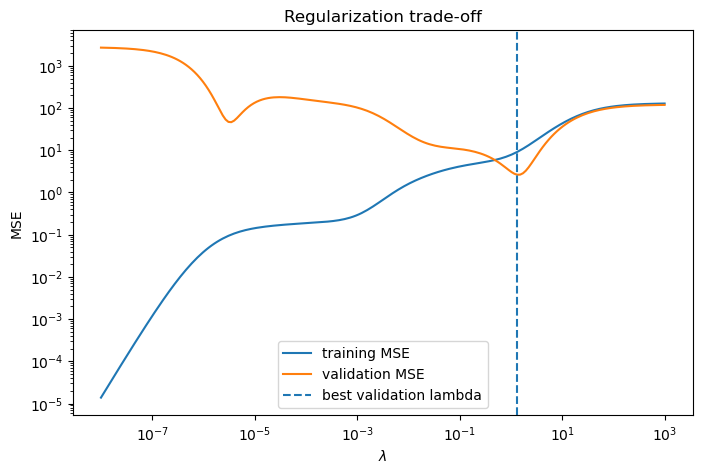

In [75]:
plt.figure(figsize=(8,5))
plt.loglog(lam_grid,train_err,label="training MSE")
plt.loglog(lam_grid,val_err,label="validation MSE")
plt.axvline(best_lambda,linestyle="--",label="best validation lambda")
plt.xlabel(r"$\lambda$")
plt.ylabel("MSE")
plt.title("Regularization trade-off")
plt.legend()
plt.show()

## 9. Final comparison including the validation-selected fit

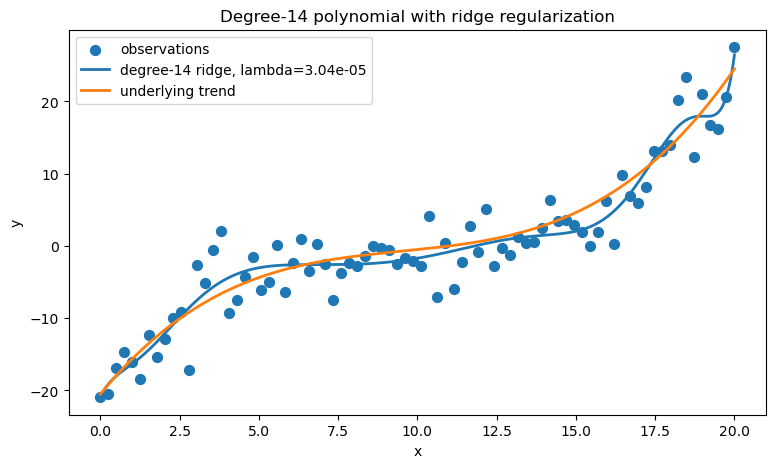

In [83]:
theta_best = ridge_fit(Phi,y,best_lambda)
yg_best = Phi_g @ theta_best

plt.figure(figsize=(9,5))
plt.scatter(x,y,s=50,label="observations")
plt.plot(xg,yg_best,linewidth=2,label=f"degree-14 ridge, lambda={best_lambda:.3g}")
plt.plot(xg,f_true(xg),linewidth=2,label="underlying trend")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Degree-14 polynomial with ridge regularization")
plt.legend()
plt.show()

# Take-home message

A degree-14 polynomial has many basis functions:

$$
\phi(x)
=
[1,x,x^2,\ldots,x^{14}].
$$

Without sufficient regularization, the model can use large high-order coefficients to chase noise.

Ridge solves

$$
\boxed{
\min_\theta
\left[
\|y-\Phi\theta\|^2
+
\lambda\|\theta\|^2
\right].
}
$$

Thus,

$$
\boxed{
\lambda\text{ small}
\Rightarrow
\text{flexible / potentially overfit}
}
$$

$$
\boxed{
\lambda\text{ intermediate}
\Rightarrow
\text{smoother and often better generalization}
}
$$

$$
\boxed{
\lambda\text{ large}
\Rightarrow
\text{strong shrinkage / underfitting}.
}
$$

This is the basic bias-variance trade-off behind ridge regression.